# Spotify Song Recommendation System

**Independent portfolio project — not affiliated with Spotify.**

This notebook reproduces the data preparation and exploratory analysis workflow from the supplied Persian notebook, then uses a nearest-neighbor model to retrieve tracks with close standardized audio-feature vectors. DBSCAN is treated as exploratory analysis rather than a hard recommendation filter because the saved run showed a highly imbalanced cluster distribution.

> A smaller feature distance means closer numeric audio-feature vectors. It is not a probability, accuracy percentage, or guarantee of perceived musical similarity.

## Dataset
Place `universal_top_spotify_songs.csv` inside the project's `data/` directory. The dataset is not bundled with this repository; confirm its license before sharing it.

## 1. Import libraries

In [12]:
from pathlib import Path
import warnings

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_columns", 50)

AUDIO_FEATURES = [
    "danceability",
    "energy",
    "loudness",
    "speechiness",
    "acousticness",
    "instrumentalness",
    "liveness",
    "valence",
    "tempo",
]

RANDOM_STATE = 42
SAMPLE_SIZE = 12_000

print("Libraries loaded successfully.")

Libraries loaded successfully.


## 2. Load the dataset

In [13]:
# This path works when Jupyter is opened from either the project root
# or the notebooks/ directory.
candidate_paths = [
    Path("data/universal_top_spotify_songs.csv"),
    Path("../data/universal_top_spotify_songs.csv"),
]

DATA_PATH = next(
    (path for path in candidate_paths if path.exists()),
    candidate_paths[0],
)

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found at {DATA_PATH}. "
        "Place universal_top_spotify_songs.csv inside the project's data/ folder."
    )

df = pd.read_csv(DATA_PATH)

print(f"Dataset shape: {df.shape}")
display(df.head())

Dataset shape: (2110316, 25)


,spotify_id,name,artists,daily_rank,daily_movement,weekly_movement,country,snapshot_date,popularity,is_explicit,duration_ms,album_name,album_release_date,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature
0,2RkZ5LkEzeHGRsmDqKwmaJ,Ordinary,Alex Warren,1,1,0,NaN,2025-06-11,95,False,186964,"You'll Be Alright, Kid (Chapter 1)",2024-09-26,0.368,0.694,2,-6.141,1,0.0600,0.704000,0.000007,0.0550,0.391,168.115,3
1,42UBPzRMh5yyz0EDPr6fr1,Manchild,Sabrina Carpenter,2,-1,48,NaN,2025-06-11,89,True,213645,Manchild,2025-06-05,0.731,0.685,7,-5.087,1,0.0572,0.122000,0.000000,0.3170,0.811,123.010,4
2,0FTmksd2dxiE5e3rWyJXs6,back to friends,sombr,3,0,1,NaN,2025-06-11,98,False,199032,back to friends,2024-12-27,0.436,0.723,1,-2.291,1,0.0301,0.000094,0.000088,0.0929,0.235,92.855,4
3,7so0lgd0zP2Sbgs2d7a1SZ,Die With A Smile,"Lady Gaga, Bruno Mars",4,0,-1,NaN,2025-06-11,91,False,251667,MAYHEM,2025-03-07,0.519,0.601,6,-7.727,0,0.0317,0.289000,0.000000,0.1260,0.498,157.964,3
4,6dOtVTDdiauQNBQEDOtlAB,BIRDS OF A FEATHER,Billie Eilish,5,1,0,NaN,2025-06-11,100,False,210373,HIT ME HARD AND SOFT,2024-05-17,0.747,0.507,2,-10.171,1,0.0358,0.200000,0.060800,0.1170,0.438,104.978,4


## 3. Inspect and clean the data

The recommendation model requires a track title, artist name, and all nine audio features. Rows missing any required value are removed. Duplicate Spotify track IDs are reduced to one record when IDs are available; rows without an ID fall back to `(name, artists)` deduplication.

In [14]:
required_columns = ["name", "artists", *AUDIO_FEATURES]
missing_columns = [column for column in required_columns if column not in df.columns]

if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

for feature in AUDIO_FEATURES:
    df[feature] = pd.to_numeric(df[feature], errors="coerce")

df_clean = df.dropna(subset=required_columns).copy()
df_clean["name"] = df_clean["name"].astype(str).str.strip()
df_clean["artists"] = df_clean["artists"].astype(str).str.strip()
df_clean = df_clean[(df_clean["name"] != "") & (df_clean["artists"] != "")]

if "spotify_id" in df_clean.columns:
    has_id = df_clean["spotify_id"].notna() & df_clean["spotify_id"].astype(str).str.strip().ne("")
    with_id = df_clean.loc[has_id].drop_duplicates(subset=["spotify_id"], keep="first")
    without_id = df_clean.loc[~has_id].drop_duplicates(subset=["name", "artists"], keep="first")
    df_clean = pd.concat([with_id, without_id], ignore_index=True)
else:
    df_clean = df_clean.drop_duplicates(subset=["name", "artists"], keep="first")

df_clean = df_clean.reset_index(drop=True)

print(f"Rows before cleaning: {len(df):,}")
print(f"Rows after cleaning:  {len(df_clean):,}")
display(df_clean[["name", "artists", *AUDIO_FEATURES]].head())

Rows before cleaning: 2,110,316
Rows after cleaning:  24,975


,name,artists,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
0,Ordinary,Alex Warren,0.368,0.694,-6.141,0.0600,0.704000,0.000007,0.0550,0.391,168.115
1,Manchild,Sabrina Carpenter,0.731,0.685,-5.087,0.0572,0.122000,0.000000,0.3170,0.811,123.010
2,back to friends,sombr,0.436,0.723,-2.291,0.0301,0.000094,0.000088,0.0929,0.235,92.855
3,Die With A Smile,"Lady Gaga, Bruno Mars",0.519,0.601,-7.727,0.0317,0.289000,0.000000,0.1260,0.498,157.964
4,BIRDS OF A FEATHER,Billie Eilish,0.747,0.507,-10.171,0.0358,0.200000,0.060800,0.1170,0.438,104.978


## 4. Create a reproducible sample

The original dataset may contain many chart snapshots for the same track. After deduplication, a fixed random sample keeps model training manageable and makes the experiment repeatable.

In [15]:
sample_size = min(SAMPLE_SIZE, len(df_clean))

df_sample = (
    df_clean.sample(n=sample_size, random_state=RANDOM_STATE)
    .reset_index(drop=True)
)

X = df_sample[AUDIO_FEATURES].astype(float).copy()

print(f"Sample size: {len(df_sample):,}")
print(f"Feature matrix shape: {X.shape}")

Sample size: 12,000
Feature matrix shape: (12000, 9)


## 5. Standardize the audio features

The nine features use different units and ranges. For example, `tempo` is measured in beats per minute while `danceability` is generally between 0 and 1.

`StandardScaler` transforms each feature so that it is centered around 0 and has a standard deviation of approximately 1. This prevents features with larger numeric scales from dominating distance calculations.

In [16]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Scaled feature matrix:", X_scaled.shape)
display(
    pd.DataFrame(X_scaled, columns=AUDIO_FEATURES)
    .describe()
    .round(2)
)

Scaled feature matrix: (12000, 9)


,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
count,12000.00,12000.00,12000.00,12000.00,12000.00,12000.00,12000.00,12000.00,12000.00
mean,-0.00,0.00,-0.00,-0.00,-0.00,0.00,0.00,0.00,0.00
std,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00
min,-4.84,-3.85,-15.37,-1.08,-1.09,-0.20,-1.17,-2.33,-4.42
25%,-0.64,-0.63,-0.42,-0.70,-0.84,-0.20,-0.61,-0.77,-0.82
50%,0.13,0.11,0.15,-0.45,-0.31,-0.20,-0.40,0.00,-0.03
75%,0.72,0.74,0.61,0.40,0.62,-0.20,0.31,0.77,0.62
max,2.27,2.02,3.12,7.28,2.90,7.62,5.66,1.99,3.87


## 6. Explore clusters with DBSCAN

DBSCAN groups dense regions and labels isolated observations as noise (`-1`). It is useful here as an exploratory analysis step.

The clustering parameters below reproduce the settings in the supplied notebook. They should be tuned and evaluated before cluster labels are used to filter recommendations.

In [17]:
dbscan = DBSCAN(
    eps=1.9,
    min_samples=12,
    n_jobs=-1,
)

cluster_labels = dbscan.fit_predict(X_scaled)
df_sample["cluster"] = cluster_labels

cluster_counts = (
    pd.Series(cluster_labels, name="cluster")
    .value_counts()
    .sort_index()
)

n_clusters = len(set(cluster_labels)) - (1 if -1 in cluster_labels else 0)
n_noise = int(np.sum(cluster_labels == -1))

print(f"Number of clusters (excluding noise): {n_clusters}")
print(f"Noise points: {n_noise:,} ({n_noise / len(cluster_labels) * 100:.1f}%)")
display(cluster_counts.to_frame("track_count"))

Number of clusters (excluding noise): 3
Noise points: 346 (2.9%)


,track_count
cluster,
-1,346
0,11635
1,12
2,7


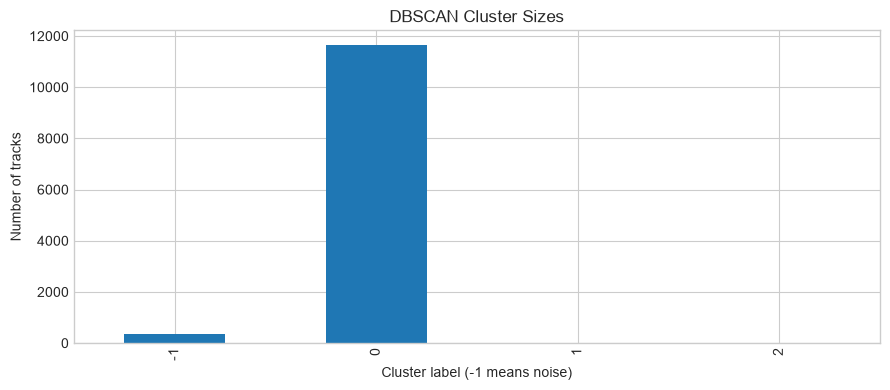

,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
cluster,,,,,,,,,
-1,0.582,0.500,-12.743,0.170,0.434,0.456,0.270,0.448,120.842
0,0.675,0.660,-6.810,0.120,0.267,0.011,0.182,0.534,122.753
1,0.577,0.175,-28.762,0.045,0.592,0.896,0.109,0.338,129.168
2,0.654,0.904,-5.097,0.040,0.030,0.864,0.209,0.333,128.588


In [18]:
plt.figure(figsize=(9, 4))
cluster_counts.plot(kind="bar")
plt.title("DBSCAN Cluster Sizes")
plt.xlabel("Cluster label (-1 means noise)")
plt.ylabel("Number of tracks")
plt.tight_layout()
plt.show()

cluster_profile = (
    df_sample.groupby("cluster")[AUDIO_FEATURES]
    .mean()
    .round(3)
)
display(cluster_profile)

### Interpreting the clustering result

A clustering algorithm is not automatically useful just because it returns cluster labels. In the rerun on the supplied CSV (2026-11-20), the 12,000-track sample produced:

- Cluster `0`: 11,635 tracks
- Cluster `1`: 12 tracks
- Cluster `2`: 7 tracks
- Noise (`-1`): 346 tracks

This means the current parameters create one dominant cluster and do not provide balanced segmentation. The package therefore keeps DBSCAN for exploration but does **not** use its labels as a hard restriction for recommendations.

A silhouette score is only calculated when at least two non-noise clusters are present. Even then, it measures geometric separation in feature space, not perceived music quality.

In [19]:
non_noise_mask = cluster_labels != -1
non_noise_labels = cluster_labels[non_noise_mask]

if len(np.unique(non_noise_labels)) >= 2:
    score = silhouette_score(
        X_scaled[non_noise_mask],
        non_noise_labels,
        sample_size=min(2_000, int(non_noise_mask.sum())),
        random_state=RANDOM_STATE,
    )
    print(f"Silhouette score on non-noise tracks: {score:.3f}")
else:
    print(
        "Silhouette score skipped: DBSCAN found fewer than two "
        "non-noise clusters."
    )

Silhouette score on non-noise tracks: 0.548


## 7. Build the recommendation engine with Nearest Neighbors

For recommendations, the model retrieves the tracks with the smallest **Euclidean distance** from the selected track in standardized feature space.

This approach is independent of DBSCAN cluster membership. It avoids the issue where almost all tracks are assigned to one large cluster.

The displayed distance is a ranking value:
- Smaller distance: closer standardized audio-feature vectors.
- It is not a percentage, probability, or accuracy score.

In [20]:
neighbor_model = NearestNeighbors(
    metric="euclidean",
    algorithm="auto",
)

neighbor_model.fit(X_scaled)

print("Nearest-neighbor index fitted.")

Nearest-neighbor index fitted.


## 8. Search for a track and recommend similar tracks

In [21]:
def search_songs(songs: pd.DataFrame, query: str, limit: int = 30) -> pd.DataFrame:
    """Search track titles and artist names using literal text matching."""
    if not isinstance(query, str) or not query.strip():
        return songs.iloc[0:0].copy()

    query = query.strip()

    title_match = songs["name"].astype(str).str.contains(
        query, case=False, na=False, regex=False
    )
    artist_match = songs["artists"].astype(str).str.contains(
        query, case=False, na=False, regex=False
    )

    return songs.loc[title_match | artist_match].head(limit).copy()


def recommend_by_index(
    track_index: int,
    top_n: int = 10,
    exclude_same_artist: bool = False,
) -> pd.DataFrame:
    """Find nearest tracks to one selected row in the sample."""
    if not 0 <= int(track_index) < len(df_sample):
        raise IndexError("track_index is outside the dataset.")

    top_n = max(1, min(int(top_n), len(df_sample) - 1))
    request_count = min(len(df_sample), max(top_n + 1, top_n * 4 + 1))

    distances, indices = neighbor_model.kneighbors(
        X_scaled[int(track_index)].reshape(1, -1),
        n_neighbors=request_count,
    )

    target_artist = str(df_sample.iloc[int(track_index)]["artists"])
    results = []

    for distance, candidate_index in zip(distances[0], indices[0]):
        candidate_index = int(candidate_index)

        if candidate_index == int(track_index):
            continue

        candidate = df_sample.iloc[candidate_index]

        if exclude_same_artist and str(candidate["artists"]) == target_artist:
            continue

        results.append({
            "name": candidate["name"],
            "artists": candidate["artists"],
            "feature_distance": float(distance),
            "cluster": int(candidate["cluster"]),
        })

        if len(results) >= top_n:
            break

    return pd.DataFrame(results)


matches = search_songs(df_sample, "Die With A Smile")

if matches.empty:
    print("The example track was not found in this sample.")
else:
    display(matches[["name", "artists"]].head(10))
    selected_index = int(matches.index[0])
    recommendations = recommend_by_index(selected_index, top_n=8)
    display(recommendations.round({"feature_distance": 3}))

,name,artists
5849,Die With A Smile,"Lady Gaga, Bruno Mars"


,name,artists,feature_distance,cluster
0,Slow Dancing,V,0.622,0
1,จะมอบความรัก,YEW,0.663,0
2,鑿,陳卓賢 Ian,0.684,0
3,Mghayer,ElGrandeToto,0.744,0
4,Styttist í það,"Baggalútur, Bryndis Jakobsdottir",0.753,0
5,Styttist í það,"Baggalútur, Bryndis Jakobsdottir",0.753,0
6,Jueves 10,Junior H,0.770,0
7,משהו אמיתי בעיניים,ששון איפרם שאולוב,0.801,0


## 9. Save artifacts for the Streamlit app and API

The app and API load the saved artifacts rather than retraining the model whenever a user opens the interface.

Run the notebook through this section before starting the application, or run the standalone training script:

```bash
python train_model.py
```

The generated files are stored in `models/`.

In [22]:
from pathlib import Path

project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
models_dir = project_root / "models"
models_dir.mkdir(parents=True, exist_ok=True)

joblib.dump(scaler, models_dir / "scaler.joblib")
joblib.dump(dbscan, models_dir / "dbscan_model.joblib")
joblib.dump(neighbor_model, models_dir / "nearest_neighbors.joblib")

df_sample.to_csv(models_dir / "songs.csv", index=False, encoding="utf-8")
np.save(models_dir / "X_scaled.npy", X_scaled)

print(f"Artifacts saved to: {models_dir.resolve()}")

Artifacts saved to: E:\project⭐\Spotify_Song_Recommender_Portfolio_Final_Fixed\models


## 10. Run the applications

From the project root directory:

### Streamlit
```bash
streamlit run app.py
```

### FastAPI (optional)
```bash
uvicorn api:app --reload --port 8000
```

Open `http://127.0.0.1:8000/docs` to inspect the API endpoints.

## Next improvements

- Tune DBSCAN and compare clustering configurations.
- Add genre or artist metadata to improve recommendation relevance.
- Evaluate recommendation rankings with human relevance judgments and metrics such as Precision@K, Recall@K, or NDCG.
- Add user feedback (like / dislike) to personalize the ranking.
- Explore audio embeddings or raw audio analysis for richer representations.
- Add genuine screenshots of the running app to the repository.

## Important limitation

This model compares numeric audio characteristics, not the full listening experience. Similar feature vectors do not guarantee that two tracks have the same genre, mood, melody, lyrics, or appeal to a particular listener.